# Farmer-Herder Conflict Risk in Southern Chad — Full Pipeline

Capstone project, BSc Software Engineering (Machine Learning), African Leadership University.

This notebook contains the complete code of the project, step by step, with its outputs.
It is generated from the scripts in `scripts/` (by `scripts/make_notebook.py`), which remain
the reference implementation used by the dashboard and the tests.

**Research question.** Do satellite-derived indicators of pasture conditions, rainfall and the
crop calendar improve the prediction of farmer-herder conflict risk in southern Chad, compared
with conflict history alone?

**Steps**
1. Download conflict events (ACLED API) — *skipped by default, data already downloaded*
2. Validated labels and target variable
3. Exploratory analysis
4. Department x month panel
5. Application database
6. Satellite indicators (Google Earth Engine) — *skipped by default, indicators already extracted*
7. Feature table (no look-ahead)
8. Research model (conflict history up to the previous month), then the operational model
   (only information really available at forecast time: conflict history delayed by 12
   months, satellite data up to the previous month), which produces the current outlook
9. Automated tests
10. Dashboard code

> Ethics: aggregated department-level data only, no ethnic or religious variables. Raw ACLED
> data are not redistributed (licence). The tool supports human decisions; it does not make them.


In [1]:
from pathlib import Path

# Project root (works whether the notebook is opened from notebooks/ or from the project root)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# Optional steps (they need credentials and take time; their outputs are already in data/)
RUN_DOWNLOAD = False   # step 1: re-download ACLED events (needs ACLED credentials in .env)
RUN_GEE = False        # step 6: re-extract satellite indicators (needs Earth Engine, ~25 min)
print("Project root:", ROOT)

Project root: C:\Users\RICHARD\Capstone project


## 1. Download conflict events (ACLED API)

```text
Download all ACLED events for Chad (2015-01-01 -> 2025-10-02) through the ACLED API.
```

In [2]:
import os
import sys
from pathlib import Path

import pandas as pd
import requests
from dotenv import load_dotenv

OUT_FILE = ROOT / "data" / "raw" / "acled_chad_2015_2025.csv"

TOKEN_URL = "https://acleddata.com/oauth/token"
API_URL = "https://acleddata.com/api/acled/read"

COUNTRY = "Chad"
START_DATE = "2015-01-01"
END_DATE = "2025-10-02"
PAGE_SIZE = 5000


def get_token(username: str, password: str) -> str:
    resp = requests.post(
        TOKEN_URL,
        data={
            "username": username,
            "password": password,
            "grant_type": "password",
            "client_id": "acled",
        },
        timeout=60,
    )
    if resp.status_code != 200:
        sys.exit(f"Authentication failed ({resp.status_code}): {resp.text[:300]}")
    return resp.json()["access_token"]


def fetch_all(token: str) -> pd.DataFrame:
    headers = {"Authorization": f"Bearer {token}"}
    rows, page = [], 1
    while True:
        params = {
            "_format": "json",
            "country": COUNTRY,
            "event_date": f"{START_DATE}|{END_DATE}",
            "event_date_where": "BETWEEN",
            "limit": PAGE_SIZE,
            "page": page,
        }
        resp = requests.get(API_URL, headers=headers, params=params, timeout=120)
        if resp.status_code != 200:
            sys.exit(f"API error, page {page} ({resp.status_code}): {resp.text[:300]}")
        data = resp.json().get("data", [])
        print(f"Page {page}: {len(data)} events")
        if not data:
            break
        rows.extend(data)
        if len(data) < PAGE_SIZE:
            break
        page += 1
    return pd.DataFrame(rows)


def main() -> None:
    load_dotenv(ROOT / ".env")
    username = os.getenv("ACLED_USERNAME")
    password = os.getenv("ACLED_PASSWORD")
    if not username or not password:
        sys.exit("ACLED_USERNAME and ACLED_PASSWORD must be set in the .env file")

    token = get_token(username, password)
    df = fetch_all(token)
    if df.empty:
        sys.exit("No events received: check the parameters against the API guide.")

    OUT_FILE.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(OUT_FILE, index=False)
    print(f"\n{len(df)} events saved to {OUT_FILE}")
    print(f"Period: {df['event_date'].min()} -> {df['event_date'].max()}")
    print(f"Countries: {df['country'].unique().tolist()}")


if RUN_DOWNLOAD:
    main()
else:
    print("Skipped: ACLED data already downloaded (set RUN_DOWNLOAD = True to re-run).")

Skipped: ACLED data already downloaded (set RUN_DOWNLOAD = True to re-run).


## 2. Validated labels and target variable

```text
Build the target variable (farmer-herder conflicts) from the manual classification
of ACLED events, and compare it with keyword filtering.

Labels (data/processed/manual_labels.csv), see docs/labeling_codebook.md:
    FH  = direct violence between farmers and herders (model target)
    AMB = communal / pastoral violence without explicit farmer-herder framing
    REL = related but non-violent event (protest, arrests, reconciliation)
    NO  = everything else (default)
```

In [3]:
from pathlib import Path

import pandas as pd

RAW = ROOT / "data" / "raw" / "acled_chad_2015_2025.csv"
LABELS = ROOT / "data" / "processed" / "manual_labels.csv"
OUT = ROOT / "data" / "processed" / "acled_chad_labeled.csv"
VALIDATION = ROOT / "data" / "processed" / "validation_sample.csv"

SOUTH = [
    "Logone Occidental", "Logone Oriental", "Mandoul", "Moyen-Chari",
    "Tandjile", "Mayo Kebbi Est", "Mayo Kebbi Ouest",
]
KEYWORDS = (
    r"herder|herdsm|pastoral|cattle|livestock|transhuman|nomad|grazing|"
    r"farmer|crop|field|farm|camel|cow|oxen|herd"
)

df = pd.read_csv(RAW)
labels = pd.read_csv(LABELS)
assert labels["event_id_cnty"].is_unique, "Duplicate IDs in manual_labels.csv"

df = df.merge(labels, on="event_id_cnty", how="left")
df["label"] = df["label"].fillna("NO")
df["event_date"] = pd.to_datetime(df["event_date"])
df["month"] = df["event_date"].dt.month
df["fatalities"] = pd.to_numeric(df["fatalities"], errors="coerce").fillna(0)
df["admin1_norm"] = (
    df["admin1"].str.normalize("NFKD").str.encode("ascii", "ignore").str.decode("ascii")
)
df["is_south"] = df["admin1_norm"].isin(SOUTH)
df["keyword_hit"] = df["notes"].str.contains(KEYWORDS, case=False, na=False)
df["target_fh"] = (df["label"] == "FH").astype(int)
# Broad target for the sensitivity analysis
df["target_broad"] = df["label"].isin(["FH", "AMB"]).astype(int)

df.to_csv(OUT, index=False)

print("=" * 70)
print("LABEL DISTRIBUTION")
print(df["label"].value_counts().to_string())

fh = df[df["target_fh"] == 1]
print("\n" + "=" * 70)
print(f"CONFIRMED FARMER-HERDER CONFLICTS: {len(fh)}")
print(f"  of which south: {fh['is_south'].sum()} ({fh['is_south'].mean():.0%})")
print(f"  total fatalities: {fh['fatalities'].sum():.0f} | "
      f"south: {fh.loc[fh['is_south'], 'fatalities'].sum():.0f}")

print("\nBy province:")
print(fh.groupby("admin1_norm").agg(events=("event_id_cnty", "size"),
                                     fatalities=("fatalities", "sum"))
      .sort_values("events", ascending=False).to_string())

print("\nBy year (south / rest):")
print(fh.groupby(["year", "is_south"]).size().unstack(fill_value=0)
      .rename(columns={True: "south", False: "rest"}).to_string())

print("\nSeasonality in the south (by month):")
print(fh[fh["is_south"]].groupby("month").size().reindex(range(1, 13), fill_value=0).to_string())

print("\nMost affected southern departments (admin2):")
print(fh[fh["is_south"]]["admin2"].value_counts().head(15).to_string())

print("\n" + "=" * 70)
print("COMPARISON WITH KEYWORD FILTERING")
tp = ((df["keyword_hit"]) & (df["target_fh"] == 1)).sum()
precision = tp / df["keyword_hit"].sum()
recall = tp / df["target_fh"].sum()
print(f"Keyword precision: {precision:.0%} | Recall: {recall:.0%}")

LABEL DISTRIBUTION
label
NO     1334
FH      154
AMB      80
REL      25

CONFIRMED FARMER-HERDER CONFLICTS: 154
  of which south: 112 (73%)
  total fatalities: 827 | south: 473

By province:
                   events  fatalities
admin1_norm                          
Logone Oriental        31          99
Moyen-Chari            22          86
Logone Occidental      15          87
Mandoul                14          38
Ouaddai                14         142
Mayo Kebbi Ouest       11          32
Guera                  11          76
Mayo Kebbi Est         10          58
Tandjile                9          73
Batha                   6          52
Salamat                 4          38
Hadjer-Lamis            2          21
Chari Baguirmi          2           4
Lac                     1          12
Kanem                   1           1
Sila                    1           8

By year (south / rest):
is_south  rest  south
year                 
2016         1      0
2018         4      1
2019       

In [4]:
# Stratified sample for blind manual validation by the author.
# Never overwrite a sample that has already been annotated.
if VALIDATION.exists():
    print(f"\n{VALIDATION.name} already exists: not regenerated (annotations preserved).")
else:
    parts = [
        df[df["label"] == "FH"].sample(30, random_state=1),
        df[df["label"] == "AMB"].sample(min(15, (df["label"] == "AMB").sum()), random_state=1),
        df[(df["label"] == "NO") & df["keyword_hit"]].sample(15, random_state=1),
    ]
    sample = pd.concat(parts).sample(frac=1, random_state=1)
    sample = sample[["event_id_cnty", "event_date", "admin1", "notes"]].assign(author_label="")
    sample.to_csv(VALIDATION, index=False)
    print(f"\nValidation sample (60 events, labels hidden): {VALIDATION}")


validation_sample.csv already exists: not regenerated (annotations preserved).


## 3. Exploratory analysis

```text
Exploratory analysis of ACLED data for Chad (2015-2025), using the validated labels.
Goal: document the concentration, trend and seasonality of farmer-herder conflict
in the south (figures for the report).
```

In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA = ROOT / "data" / "processed" / "acled_chad_labeled.csv"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA, parse_dates=["event_date"])
fh = df[df["target_fh"] == 1]

print("Events per year (all ACLED events, Chad):")
print(df.groupby("year").size().to_string())
print("\nEvent types:")
print(df["event_type"].value_counts().to_string())
print("\nGeographic precision (1-2 = precise, 3 = province level):")
print(df["geo_precision"].value_counts().sort_index().to_string())

by_prov = (
    fh.groupby("admin1_norm")
    .agg(events=("event_id_cnty", "size"), fatalities=("fatalities", "sum"),
         south=("is_south", "first"))
    .sort_values("events", ascending=False)
)
season = fh[fh["is_south"]].groupby("month").size().reindex(range(1, 13), fill_value=0)
yearly = (fh.groupby(["year", "is_south"]).size().unstack(fill_value=0)
          .rename(columns={True: "South", False: "Rest of Chad"}))

Events per year (all ACLED events, Chad):
year
2015     40
2016     40
2017     26
2018     83
2019    211
2020    159
2021    251
2022    269
2023    187
2024    169
2025    158

Event types:
event_type
Violence against civilians    405
Battles                       380
Protests                      377
Strategic developments        193
Riots                         172
Explosions/Remote violence     66

Geographic precision (1-2 = precise, 3 = province level):
geo_precision
1    970
2    541
3     82


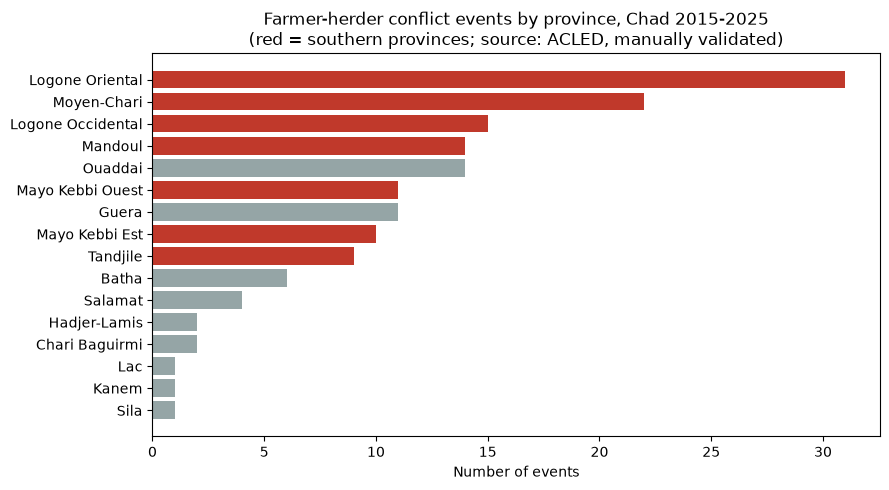

In [6]:
# Figure 1: events by province
fig, ax = plt.subplots(figsize=(9, 5))
colors = ["#c0392b" if s else "#95a5a6" for s in by_prov["south"]]
ax.barh(by_prov.index[::-1], by_prov["events"][::-1], color=colors[::-1])
ax.set_xlabel("Number of events")
ax.set_title("Farmer-herder conflict events by province, Chad 2015-2025\n"
             "(red = southern provinces; source: ACLED, manually validated)")
plt.tight_layout()
plt.savefig(FIG_DIR / "fh_by_province.png", dpi=150)
plt.show()

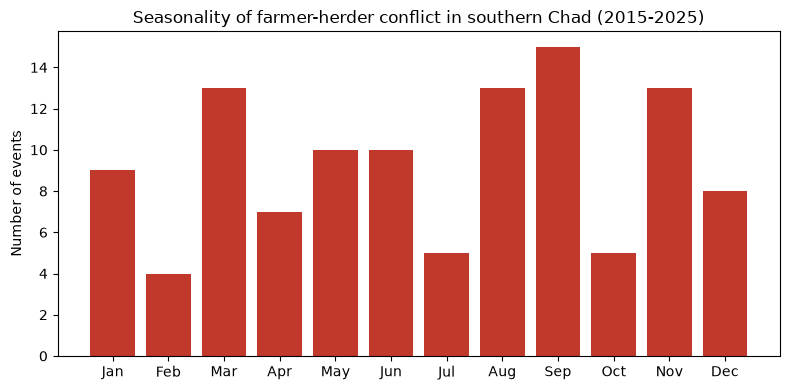

In [7]:
# Figure 2: seasonality in the south
fig, ax = plt.subplots(figsize=(8, 4))
labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
ax.bar(labels, season.values, color="#c0392b")
ax.set_ylabel("Number of events")
ax.set_title("Seasonality of farmer-herder conflict in southern Chad (2015-2025)")
plt.tight_layout()
plt.savefig(FIG_DIR / "fh_south_seasonality.png", dpi=150)
plt.show()

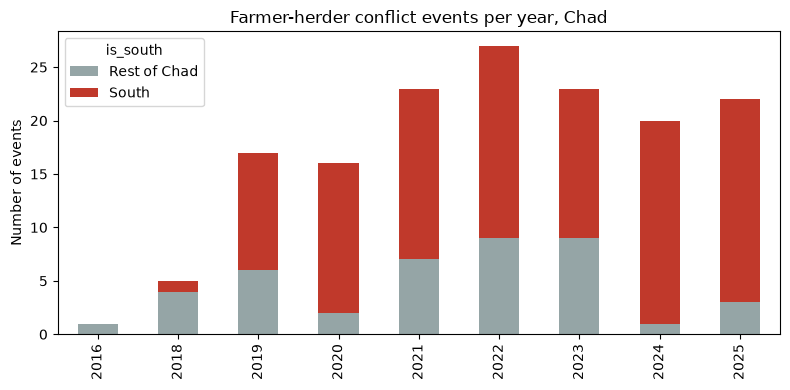

In [8]:
# Figure 3: yearly trend
ax = yearly.plot(kind="bar", stacked=True, color=["#95a5a6", "#c0392b"], figsize=(8, 4))
ax.set_ylabel("Number of events")
ax.set_xlabel("")
ax.set_title("Farmer-herder conflict events per year, Chad")
plt.tight_layout()
plt.savefig(FIG_DIR / "fh_yearly_trend.png", dpi=150)
plt.show()

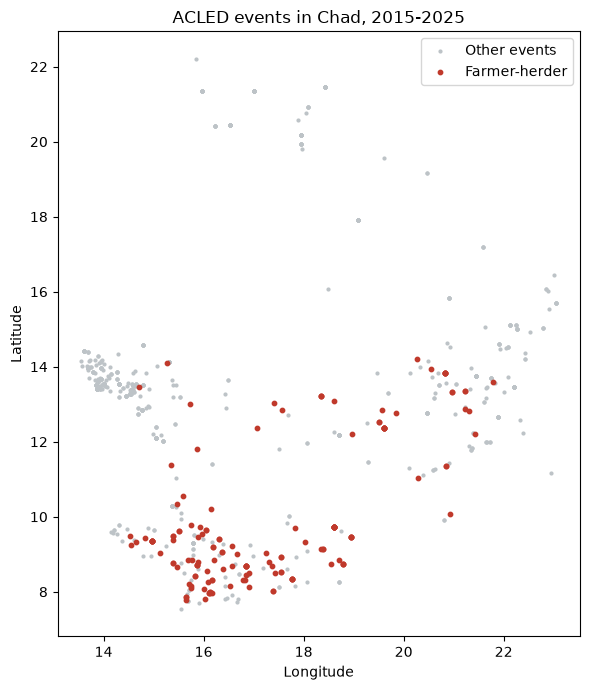


Figures saved to C:\Users\RICHARD\Capstone project\reports\figures


In [9]:
# Figure 4: map of events
fig, ax = plt.subplots(figsize=(6, 7))
other = df[df["target_fh"] == 0]
ax.scatter(other["longitude"], other["latitude"], s=4, c="#bdc3c7", label="Other events")
ax.scatter(fh["longitude"], fh["latitude"], s=10, c="#c0392b", label="Farmer-herder")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("ACLED events in Chad, 2015-2025")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "map_events.png", dpi=150)
plt.show()

print(f"\nFigures saved to {FIG_DIR}")

## 4. Department x month panel

```text
Build the department x month panel for southern Chad (the model's unit of analysis).

- Boundaries: geoBoundaries TCD ADM1/ADM2 (2019, 70 departments)
- Events: data/processed/acled_chad_labeled.csv (output of build_target.py)
- Each event is assigned to a department by spatial join (lat/lon), because
  ACLED admin2 names and geoBoundaries names do not match.

Outputs:
    data/processed/south_departments.geojson
    data/processed/panel_dept_month.csv
```

In [10]:
from pathlib import Path

import geopandas as gpd
import pandas as pd

EXT = ROOT / "data" / "external"
PROC = ROOT / "data" / "processed"

SOUTH_ADM1 = [
    "Logone Occidental", "Logone Oriental", "Mandoul", "Moyen-Chari",
    "Tandjilé", "Mayo-Kebbi Est", "Mayo-Kebbi Ouest",
]
# ACLED coverage of Chad is poor before 2019; data available up to September 2025.
# 2017-2018 are only burn-in years for the history features (up to 24-month lags);
# modelling and the app start in 2019.
START, END = "2017-01", "2025-09"

adm1 = gpd.read_file(EXT / "tcd_adm1.geojson")[["shapeName", "geometry"]]
adm2 = gpd.read_file(EXT / "tcd_adm2.geojson")[["shapeName", "shapeID", "geometry"]]
adm1 = adm1.rename(columns={"shapeName": "province"})
adm2 = adm2.rename(columns={"shapeName": "department", "shapeID": "dept_id"})

In [11]:
# Province of each department (via an interior point)
pts = adm2.copy()
pts["geometry"] = adm2.representative_point()
adm2["province"] = gpd.sjoin(pts, adm1, predicate="within")["province"]
south = adm2[adm2["province"].isin(SOUTH_ADM1)].reset_index(drop=True)
assert south["province"].nunique() == len(SOUTH_ADM1), "Missing southern province"
south.to_file(PROC / "south_departments.geojson", driver="GeoJSON")
print(f"{len(south)} departments in the {len(SOUTH_ADM1)} southern provinces")

26 departments in the 7 southern provinces


In [12]:
# Spatial assignment of ACLED events
ev = pd.read_csv(PROC / "acled_chad_labeled.csv", parse_dates=["event_date"])
ev = gpd.GeoDataFrame(
    ev, geometry=gpd.points_from_xy(ev["longitude"], ev["latitude"]), crs="EPSG:4326"
)
ev = gpd.sjoin(ev, adm2[["dept_id", "geometry"]], predicate="within", how="left")
print(f"Events outside all department polygons: {ev['dept_id'].isna().sum()}")
ev["ym"] = ev["event_date"].dt.to_period("M")
ev["fatalities_fh"] = ev["fatalities"].where(ev["target_fh"] == 1, 0)

Events outside all department polygons: 0


In [13]:
# Full department x month panel (including months without events)
months = pd.period_range(START, END, freq="M")
panel = pd.MultiIndex.from_product(
    [south["dept_id"], months], names=["dept_id", "ym"]
).to_frame(index=False)
panel = panel.merge(south[["dept_id", "department", "province"]], on="dept_id")

agg = (
    ev[ev["dept_id"].isin(south["dept_id"])]
    .groupby(["dept_id", "ym"])
    .agg(
        n_fh=("target_fh", "sum"),
        n_broad=("target_broad", "sum"),
        fatalities_fh=("fatalities_fh", "sum"),
        n_all_events=("event_id_cnty", "size"),
    )
    .reset_index()
)
panel = panel.merge(agg, on=["dept_id", "ym"], how="left").fillna(
    {"n_fh": 0, "n_broad": 0, "fatalities_fh": 0, "n_all_events": 0}
)
panel["y_fh"] = (panel["n_fh"] > 0).astype(int)
panel["y_broad"] = (panel["n_broad"] > 0).astype(int)
panel["year"] = panel["ym"].dt.year
panel["month"] = panel["ym"].dt.month
panel["ym"] = panel["ym"].astype(str)
panel.to_csv(PROC / "panel_dept_month.csv", index=False)

study = panel[panel["year"] >= 2019]
print(f"\nPanel: {len(panel)} rows ({len(south)} departments x {len(months)} months)")
print(f"Department-months (2019+) with at least one FH conflict: {study['y_fh'].sum()} "
      f"({study['y_fh'].mean():.1%})")
print(f"With the broad target (FH + AMB): {study['y_broad'].sum()} ({study['y_broad'].mean():.1%})")
print("\nFH conflicts by department (top 10):")
print(study.groupby(["province", "department"])["n_fh"].sum()
      .sort_values(ascending=False).head(10).to_string())


Panel: 2730 rows (26 departments x 105 months)
Department-months (2019+) with at least one FH conflict: 74 (3.5%)
With the broad target (FH + AMB): 91 (4.3%)

FH conflicts by department (top 10):
province           department  
Logone Oriental    Monts de Lam    18.0
Moyen-Chari        Lac Iro         12.0
Mandoul            Barh-Sara        9.0
Mayo-Kebbi Ouest   Mayo-Dallah      9.0
Moyen-Chari        Bahr-Köh         8.0
Logone Occidental  Lac Wey          7.0
Logone Oriental    La Pendé         6.0
Mayo-Kebbi Est     Kabbia           6.0
Tandjilé           Tandjilé Est     5.0
Logone Occidental  Dodjé            4.0


## 5. Application database

```text
Create / refresh the application's SQLite database (data/app.db).

Tables:
    departments : southern departments (id, name, province, GeoJSON geometry)
    panel       : department x month panel (observed conflicts, targets)
    features    : explanatory variables (reserved for satellite indicators)
    predictions : model risk estimates (written by train_models.py)

Raw ACLED notes are not stored (ACLED licence): aggregates only.
```

In [14]:
import sqlite3
from pathlib import Path

import geopandas as gpd
import pandas as pd

PROC = ROOT / "data" / "processed"
DB = ROOT / "data" / "app.db"

SCHEMA = """
CREATE TABLE IF NOT EXISTS departments (
    dept_id     TEXT PRIMARY KEY,
    department  TEXT NOT NULL,
    province    TEXT NOT NULL,
    geometry    TEXT NOT NULL
);
CREATE TABLE IF NOT EXISTS panel (
    dept_id       TEXT NOT NULL REFERENCES departments(dept_id),
    ym            TEXT NOT NULL,
    year          INTEGER,
    month         INTEGER,
    n_fh          INTEGER,
    n_broad       INTEGER,
    fatalities_fh INTEGER,
    n_all_events  INTEGER,
    y_fh          INTEGER,
    y_broad       INTEGER,
    PRIMARY KEY (dept_id, ym)
);
CREATE TABLE IF NOT EXISTS features (
    dept_id TEXT NOT NULL REFERENCES departments(dept_id),
    ym      TEXT NOT NULL,
    name    TEXT NOT NULL,
    value   REAL,
    PRIMARY KEY (dept_id, ym, name)
);
CREATE TABLE IF NOT EXISTS predictions (
    dept_id     TEXT NOT NULL REFERENCES departments(dept_id),
    ym          TEXT NOT NULL,
    model       TEXT NOT NULL,
    risk        REAL NOT NULL,
    created_at  TEXT DEFAULT CURRENT_TIMESTAMP,
    PRIMARY KEY (dept_id, ym, model)
);
"""

south = gpd.read_file(PROC / "south_departments.geojson")
panel = pd.read_csv(PROC / "panel_dept_month.csv")
panel = panel[panel["year"] >= 2019]  # 2018 = burn-in year for history features

with sqlite3.connect(DB) as con:
    con.executescript(SCHEMA)
    con.execute("DELETE FROM panel")
    con.execute("DELETE FROM departments")
    con.executemany(
        "INSERT INTO departments VALUES (?, ?, ?, ?)",
        [(r.dept_id, r.department, r.province, gpd.GeoSeries([r.geometry]).to_json())
         for r in south.itertuples()],
    )
    cols = ["dept_id", "ym", "year", "month", "n_fh", "n_broad",
            "fatalities_fh", "n_all_events", "y_fh", "y_broad"]
    con.executemany(
        f"INSERT INTO panel ({', '.join(cols)}) VALUES ({', '.join('?' * len(cols))})",
        panel[cols].astype({c: int for c in cols[2:]}).itertuples(index=False),
    )
    for t in ["departments", "panel", "features", "predictions"]:
        print(f"{t:12s}: {con.execute(f'SELECT COUNT(*) FROM {t}').fetchone()[0]} rows")
print(f"Database: {DB}")

departments : 26 rows
panel       : 2106 rows


features    : 1040 rows
predictions : 1560 rows
Database: C:\Users\RICHARD\Capstone project\data\app.db


## 6. Satellite indicators (Google Earth Engine)

```text
Extract monthly satellite indicators per southern department (Google Earth Engine).

Prerequisites:
    1. Earth Engine account + registered Google Cloud project (non-commercial use).
    2. In .env: EE_PROJECT=your-cloud-project-id
    3. Once: earthengine authenticate

Output variables (one row per department x month, 2018-01 -> END_MONTH):
    South (per department)
        south_ndvi_crop        mean NDVI over cropland (MODIS MOD13Q1)
        south_ndvi_crop_anom   deviation from the 2003-2017 mean of the same calendar month
        south_ndvi_crop_delta  change from the previous month (drying / harvest signal)
        south_rain_mm          monthly rainfall (CHIRPS)
        south_rain_anom        deviation from the 1991-2017 mean of the same calendar month
        south_cropland_frac    cropland share (ESA WorldCover 2021, static)
        south_water_occ        mean surface-water occurrence (JRC GSW, static)
        south_pop_density      population density (WorldPop 2020, static)
    North (herd departure zones: Batha, Guera, Salamat, Ouaddai; same value for all departments)
        north_ndvi_anom        mean NDVI anomaly
        north_rain_anom        monthly rainfall anomaly

The one-month lag (no look-ahead) is applied afterwards in build_features.py.

Incremental: if satellite_features.csv already exists, only the missing months up to
END_MONTH are extracted and appended. Set END_MONTH to the last complete month available
in both CHIRPS and MODIS.
```

In [15]:
if RUN_GEE:
    import os
    import sys
    from pathlib import Path

    import ee
    import geopandas as gpd
    import pandas as pd
    from dotenv import load_dotenv

    PROC = ROOT / "data" / "processed"
    EXT = ROOT / "data" / "external"
    OUT = PROC / "satellite_features.csv"

    load_dotenv(ROOT / ".env")
    project = os.getenv("EE_PROJECT")
    if not project:
        sys.exit("EE_PROJECT missing from .env (ID of the Google Cloud project linked to Earth Engine).")
    ee.Initialize(project=project)

    NORTH_ADM1 = ["Batha", "Guéra", "Salamat", "Ouaddaï"]
    END_MONTH = "2026-09"
    existing = pd.read_csv(OUT) if OUT.exists() else None
    first = (pd.Period(existing["ym"].max(), freq="M") + 1) if existing is not None else pd.Period("2017-12", freq="M")
    MONTHS = pd.period_range(first, END_MONTH, freq="M")
    print(f"Months to extract: {len(MONTHS)} ({MONTHS[0] if len(MONTHS) else None} -> {END_MONTH})")
    if len(MONTHS) == 0:
        sys.exit("Nothing to extract: satellite_features.csv is already up to date.")
    SCALE_NDVI = 250
    SCALE_RAIN = 5566


    def to_fc(gdf, id_col):
        gdf = gdf.copy()
        gdf["geometry"] = gdf.geometry.simplify(0.005)
        feats = [ee.Feature(ee.Geometry(g.__geo_interface__), {id_col: i})
                 for i, g in zip(gdf[id_col], gdf.geometry)]
        return ee.FeatureCollection(feats)


    south = gpd.read_file(PROC / "south_departments.geojson")
    depts = to_fc(south, "dept_id")
    adm1 = gpd.read_file(EXT / "tcd_adm1.geojson")
    assert adm1["shapeName"].isin(NORTH_ADM1).sum() == 4, "Northern province not found"
    north = adm1[adm1["shapeName"].isin(NORTH_ADM1)].dissolve()
    north_geom = ee.Geometry(north.geometry.iloc[0].simplify(0.01).__geo_interface__)

    # --- Collections ---
    ndvi = ee.ImageCollection("MODIS/061/MOD13Q1").select("NDVI")
    rain = ee.ImageCollection("UCSB-CHG/CHIRPS/PENTAD").select("precipitation")
    cropland = ee.ImageCollection("ESA/WorldCover/v200").first().eq(40)


    def monthly_ndvi(y, m):
        start = ee.Date.fromYMD(y, m, 1)
        return ndvi.filterDate(start, start.advance(1, "month")).mean().multiply(0.0001)


    def monthly_rain(y, m):
        start = ee.Date.fromYMD(y, m, 1)
        return rain.filterDate(start, start.advance(1, "month")).sum()


    def clim(collection_fn, years, m):
        return ee.ImageCollection([collection_fn(y, m) for y in years]).mean()


    ndvi_clim = {m: clim(monthly_ndvi, range(2003, 2018), m) for m in range(1, 13)}
    rain_clim = {m: clim(monthly_rain, range(1991, 2018), m) for m in range(1, 13)}

    # --- Static variables ---
    static_img = ee.Image.cat([
        cropland.rename("south_cropland_frac"),
        ee.Image("JRC/GSW1_4/GlobalSurfaceWater").select("occurrence").unmask(0)
          .divide(100).rename("south_water_occ"),
        ee.ImageCollection("WorldPop/GP/100m/pop").filter(ee.Filter.eq("country", "TCD"))
          .filter(ee.Filter.eq("year", 2020)).first()
          .divide(0.01).rename("south_pop_density"),  # people per 100 m pixel / 0.01 km2
    ])
    static = static_img.reduceRegions(depts, ee.Reducer.mean(), scale=250).getInfo()
    static_df = pd.DataFrame([f["properties"] for f in static["features"]])
    print("Static variables extracted.")

    # --- Monthly variables ---
    rows = []
    for p in MONTHS:
        y, m = p.year, p.month
        nd = monthly_ndvi(y, m)
        nd_crop = nd.updateMask(cropland)
        rn = monthly_rain(y, m)
        img = ee.Image.cat([
            nd_crop.rename("south_ndvi_crop"),
            nd_crop.subtract(ndvi_clim[m]).rename("south_ndvi_crop_anom"),
        ])
        r_ndvi = img.reduceRegions(depts, ee.Reducer.mean(), scale=SCALE_NDVI).getInfo()
        r_rain = ee.Image.cat([rn.rename("south_rain_mm"), rn.subtract(rain_clim[m]).rename("south_rain_anom")]) \
            .reduceRegions(depts, ee.Reducer.mean(), scale=SCALE_RAIN).getInfo()
        n_vals = ee.Image.cat([
            nd.subtract(ndvi_clim[m]).rename("north_ndvi_anom"),
            rn.subtract(rain_clim[m]).rename("north_rain_anom"),
        ]).reduceRegion(ee.Reducer.mean(), north_geom, scale=1000, maxPixels=1e10).getInfo()
        for a, b in zip(r_ndvi["features"], r_rain["features"]):
            rows.append({"ym": str(p), **a["properties"],
                         **{k: v for k, v in b["properties"].items() if k != "dept_id"},
                         **n_vals})
        print(f"{p} done")

    sat = pd.DataFrame(rows).merge(static_df, on="dept_id")
    if existing is not None:
        sat = pd.concat([existing.drop(columns=["south_ndvi_crop_delta"]), sat], ignore_index=True)
    sat = sat.sort_values(["dept_id", "ym"])
    sat["south_ndvi_crop_delta"] = sat.groupby("dept_id")["south_ndvi_crop"].diff()
    sat = sat[sat["ym"] >= "2018-01"]
    sat.to_csv(OUT, index=False)
    print(f"\n{OUT}: {len(sat)} rows, columns: {[c for c in sat.columns if c.startswith(("south_", "north_"))]}")
else:
    print("Skipped: satellite indicators already in data/processed/satellite_features.csv (set RUN_GEE = True to re-extract).")

Skipped: satellite indicators already in data/processed/satellite_features.csv (set RUN_GEE = True to re-extract).


## 7. Feature table (no look-ahead)

```text
Build the department x month feature table.

No look-ahead rule: to predict month t, only information available at the end of
month t-1 is used (every variable is lagged by at least one month).

Feature groups (prefixes):
    h_      conflict history up to month t-1                    -> research models A, B, C
    o_      conflict history up to month t-13                   -> operational models
            (ACLED Research-tier data are released with a 12-month delay, so in real use the
            most recent conflict information available at the start of month t is t-13)
    south_  satellite conditions in the south (month t-1)
    north_  satellite conditions in the northern departure zones (month t-1)
The south_ / north_ columns come from data/processed/satellite_features.csv (gee_extract.py)
and are added automatically when that file exists.

Rows are added after the end of the conflict data (targets unknown):
    - research forecast month: the month after the last ACLED month;
    - operational months: up to the month after the last satellite month. Only o_, south_,
      north_ and seasonal features are defined there; h_ features are left empty because the
      recent conflict history they need is not available.
```

In [16]:
from pathlib import Path

import geopandas as gpd
import numpy as np
import pandas as pd

PROC = ROOT / "data" / "processed"
LAG = 12  # ACLED publication delay (months)

panel = pd.read_csv(PROC / "panel_dept_month.csv")
panel["ym"] = pd.PeriodIndex(panel["ym"], freq="M")
south = gpd.read_file(PROC / "south_departments.geojson")
sat_path = PROC / "satellite_features.csv"
sat = pd.read_csv(sat_path) if sat_path.exists() else None

DATA_END = panel["ym"].max()  # last month with conflict data
OPS_END = (pd.Period(sat["ym"].max(), freq="M") + 1) if sat is not None else DATA_END + 1
OPS_END = min(OPS_END, DATA_END + 1 + LAG)  # o_ features need conflicts up to t-13

In [17]:
# Add the months after the end of the conflict data (unknown targets)
future_months = pd.period_range(DATA_END + 1, OPS_END, freq="M")
future = pd.concat([south[["dept_id", "department", "province"]].assign(ym=m)
                    for m in future_months], ignore_index=True)
panel = pd.concat([panel, future], ignore_index=True)
panel["year"] = panel["ym"].dt.year
panel["month"] = panel["ym"].dt.month
panel = panel.sort_values(["dept_id", "ym"]).reset_index(drop=True)

In [18]:
# --- Neighbourhood (southern departments sharing a border) ---
geo = south.set_index("dept_id")["geometry"]
neighbors = {
    d: [o for o in geo.index if o != d and geo[d].touches(geo[o])] for d in geo.index
}
prov_of = south.set_index("dept_id")["province"]
same_prov = {d: list(prov_of.index[(prov_of == prov_of[d]) & (prov_of.index != d)])
             for d in prov_of.index}

In [19]:
# --- Monthly conflict counts (0 when no event; unknown after DATA_END) ---
counts = ["n_fh", "n_broad", "n_all_events", "fatalities_fh"]
wide = {}
for c in counts:
    w = panel.pivot(index="ym", columns="dept_id", values=c)
    w.loc[w.index <= DATA_END] = w.loc[w.index <= DATA_END].fillna(0)
    wide[c] = w


def roll(df, k):
    return df.rolling(k, min_periods=1).sum()


def to_long(df, name):
    return df.stack(future_stack=True).rename(name)


def months_since(series_wide):
    """Months since the last conflict in the lagged series (capped at 36)."""
    out = pd.DataFrame(index=series_wide.index, columns=series_wide.columns, dtype=float)
    for d in series_wide.columns:
        last, vals = None, []
        for i, v in enumerate(series_wide[d].fillna(0).to_numpy()):
            if v > 0:
                last = i
            vals.append(36.0 if last is None else min(i - last, 36))
        out[d] = vals
    return out


def history_features(shift, prefix, short_windows):
    """Conflict-history features using counts up to month t-shift."""
    past = {c: w.shift(shift) for c, w in wide.items()}
    fh = past["n_fh"]
    feats = [
        to_long(roll(fh, 12), f"{prefix}fh_12m"),
        to_long(fh.cumsum(), f"{prefix}fh_cum"),
        to_long(roll(past["n_broad"], 12), f"{prefix}broad_12m"),
        to_long(roll(past["n_all_events"], 12), f"{prefix}allev_12m"),
        to_long(roll(past["fatalities_fh"], 12), f"{prefix}fatal_12m"),
        to_long(pd.DataFrame({d: roll(fh, 12)[neighbors[d]].sum(axis=1) for d in fh.columns}),
                f"{prefix}nb_fh_12m"),
        to_long(pd.DataFrame({d: roll(fh, 12)[same_prov[d]].sum(axis=1) for d in fh.columns}),
                f"{prefix}prov_fh_12m"),
        to_long(months_since(fh), f"{prefix}months_since_fh"),
    ]
    if short_windows:
        feats += [
            to_long(fh, f"{prefix}fh_1m"),
            to_long(roll(fh, 3), f"{prefix}fh_3m"),
            to_long(pd.DataFrame({d: roll(fh, 3)[neighbors[d]].sum(axis=1)
                                  for d in fh.columns}), f"{prefix}nb_fh_3m"),
        ]
    out = pd.concat(feats, axis=1)
    out.index.names = ["ym", "dept_id"]
    # Only defined while the lagged window lies inside the conflict data
    out.loc[out.index.get_level_values("ym") > DATA_END + shift] = np.nan
    return out.reset_index()


research = history_features(1, "h_", short_windows=True)      # conflicts up to t-1
operational = history_features(1 + LAG, "o_", short_windows=False)  # conflicts up to t-13
X = panel.merge(research, on=["ym", "dept_id"], how="left")
X = X.merge(operational, on=["ym", "dept_id"], how="left")

In [20]:
# Seasonality (known in advance, no leakage)
X["h_month_sin"] = np.sin(2 * np.pi * X["month"] / 12)
X["h_month_cos"] = np.cos(2 * np.pi * X["month"] / 12)

In [21]:
# --- Satellite variables (if available), lagged by one month ---
if sat is not None:
    sat["ym"] = pd.PeriodIndex(sat["ym"], freq="M") + 1  # information from t-1 used at t
    sat_cols = [c for c in sat.columns if c.startswith(("south_", "north_"))]
    X = X.merge(sat[["dept_id", "ym"] + sat_cols], on=["dept_id", "ym"], how="left")
    print(f"Satellite variables added: {len(sat_cols)}")
else:
    print("No satellite variables yet (satellite_features.csv missing): model A only.")

X["ym"] = X["ym"].astype(str)
X.to_csv(PROC / "features.csv", index=False)
cols = [c for c in X.columns if c.startswith(("h_", "o_", "south_", "north_"))]
print(f"features.csv: {len(X)} rows, {len(cols)} features")
print(f"Conflict data end: {DATA_END} | research forecast month: {DATA_END + 1} | "
      f"operational months up to: {OPS_END}")

Satellite variables added: 10
features.csv: 3068 rows, 31 features
Conflict data end: 2025-09 | research forecast month: 2025-10 | operational months up to: 2026-10


## 8. Research model: training, evaluation and SHAP (quarterly horizon)

```text
Train and evaluate the farmer-herder conflict risk models.

Unit of analysis (--unit):
    month   : risk of >= 1 conflict in the department during the month
    quarter : risk of >= 1 conflict during the quarter starting that month,
              using only information available at the start of the quarter

Temporal split (no random shuffling):
    model selection 2019-2023 | test 2024 - 2025-09 (used once, never for tuning)
Hyperparameters are selected by rolling-origin validation (validate on 2021, 2022
and 2023, each time training on the preceding years), then the model is refit on
2019-2023 and evaluated once on the test period.

Modes (--mode):
    research    : conflict history up to month t-1 (answers the research question)
        rule : risk = conflicts in the last 12 months (baseline to beat)
        A    : conflict history (h_)
        B    : A + southern satellite conditions (south_)
        C    : B + northern satellite conditions (north_)
    operational : only information really available at forecast time, i.e. conflict history
                  up to month t-13 (ACLED 12-month delay) plus satellite data up to t-1;
                  produces a genuine forecast beyond the end of the conflict data
        rule : risk = conflicts in the 12 months up to t-13
        OA   : lagged conflict history (o_) + seasonality
        OB   : OA + southern and northern satellite conditions
    x {logistic regression, XGBoost}

Metrics: PR-AUC (primary), ROC-AUC, recall and precision within the 10% of
department-months ranked most at risk, Brier score; 95% CI by month-block bootstrap.

Outputs: reports/metrics_<mode>_<unit>.csv, reports/figures/*_<mode>_<unit>.png,
         predictions in data/app.db
```

In [22]:
import json
import sqlite3
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss,
                             precision_recall_curve, roc_auc_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=UserWarning)

PROC = ROOT / "data" / "processed"
REPORTS = ROOT / "reports"
FIGS = REPORTS / "figures"
FIGS.mkdir(parents=True, exist_ok=True)
DB = ROOT / "data" / "app.db"
SEED = 42
TOP = 0.10

from types import SimpleNamespace

In [23]:
# Research model, quarterly horizon (the other runs follow at the end of this step)
ARGS = SimpleNamespace(unit="quarter", mode="research", fixed_model=None)
UNIT, MODE = ARGS.unit, ARGS.mode
TAG = f"{MODE}_{UNIT}"
VAL_YEARS = [2021, 2022, 2023]

df = pd.read_csv(PROC / "features.csv")
if UNIT == "quarter":
    # Target = at least one conflict in months t, t+1, t+2; rows = first month of each quarter
    df = df.sort_values(["dept_id", "ym"]).reset_index(drop=True)
    for y in ["y_fh", "y_broad"]:
        g = df.groupby("dept_id")[y]
        df[y] = pd.concat([df[y], g.shift(-1), g.shift(-2)], axis=1).max(axis=1, skipna=False)
    df = df[df["month"].isin([1, 4, 7, 10])]
df = df[df["year"] >= 2019].reset_index(drop=True)
print(f"Mode: {MODE} | unit of analysis: {UNIT}")
forecast = df[df["y_fh"].isna()].copy()
df = df[df["y_fh"].notna()].copy()
df["y_fh"] = df["y_fh"].astype(int)
df["y_broad"] = df["y_broad"].astype(int)

train = df[df["year"] <= 2022]
val = df[df["year"] == 2023]
trval = df[df["year"] <= 2023]
test = df[df["year"] >= 2024]

season = ["h_month_sin", "h_month_cos"]
h_cols = [c for c in df.columns if c.startswith("h_")]
o_cols = [c for c in df.columns if c.startswith("o_")] + season
s_cols = [c for c in df.columns if c.startswith("south_")]
n_cols = [c for c in df.columns if c.startswith("north_")]
if MODE == "research":
    SETS = {"A": h_cols}
    if s_cols:
        SETS["B"] = h_cols + s_cols
    if n_cols:
        SETS["C"] = h_cols + s_cols + n_cols
    RULE = ("h_fh_12m", "h_fh_cum")
else:
    SETS = {"OA": o_cols}
    if s_cols or n_cols:
        SETS["OB"] = o_cols + s_cols + n_cols
    RULE = ("o_fh_12m", "o_fh_cum")

Mode: research | unit of analysis: quarter


In [24]:
# Leakage guard: outcome columns of the predicted month must never be features
OUTCOMES = {"n_fh", "n_broad", "n_all_events", "fatalities_fh", "y_fh", "y_broad"}
for name, cols in SETS.items():
    assert not OUTCOMES & set(cols), f"Leakage in feature set {name}: {OUTCOMES & set(cols)}"

print(f"Model selection 2019-2023: {len(trval)} rows ({trval['y_fh'].sum()} positives) | "
      f"test 2024-2025: {len(test)} rows ({test['y_fh'].sum()} positives)")
print(f"Feature sets: { {k: len(v) for k, v in SETS.items()} }")

Model selection 2019-2023: 520 rows (47 positives) | test 2024-2025: 182 rows (20 positives)
Feature sets: {'A': 13, 'B': 21, 'C': 23}


In [25]:
# ---------------- Metrics ----------------
def top_k(y, p, frac=TOP):
    """Recall and precision within the top `frac` of rows ranked by risk."""
    k = max(1, int(round(frac * len(y))))
    idx = np.argsort(-p, kind="stable")[:k]
    hits = y[idx].sum()
    return hits / max(y.sum(), 1), hits / k


def metrics(y, p, months, probabilistic=True, n_boot=1000):
    """Evaluation metrics, with a month-block bootstrap CI for PR-AUC."""
    y, p = np.asarray(y), np.asarray(p)
    rec, prec = top_k(y, p)
    out = {
        "pr_auc": average_precision_score(y, p),
        "roc_auc": roc_auc_score(y, p),
        "recall_top10": rec,
        "precision_top10": prec,
        "brier": brier_score_loss(y, p) if probabilistic else np.nan,
        "prevalence": y.mean(),
    }
    # Month-block bootstrap (respects correlation between departments in the same month)
    rng = np.random.default_rng(SEED)
    um = np.unique(months)
    groups = {m: np.where(months == m)[0] for m in um}
    boots = []
    for _ in range(n_boot):
        idx = np.concatenate([groups[m] for m in rng.choice(um, len(um))])
        if y[idx].sum() > 0:
            boots.append(average_precision_score(y[idx], p[idx]))
    out["pr_auc_lo"], out["pr_auc_hi"] = np.percentile(boots, [2.5, 97.5])
    return out

In [26]:
# ---------------- Models ----------------
def make_lr(C):
    return make_pipeline(
        StandardScaler(),
        LogisticRegression(C=C, class_weight="balanced", max_iter=2000),
    )


def make_xgb(depth, n_est, mcw, spw):
    return XGBClassifier(
        max_depth=depth, n_estimators=n_est, learning_rate=0.05, min_child_weight=mcw,
        subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw, eval_metric="logloss",
        random_state=SEED, n_jobs=4,
    )


def grid(kind, ytr):
    """Small hyperparameter grid for each model family."""
    if kind == "logreg":
        return [("C=%g" % C, lambda C=C: make_lr(C)) for C in (0.01, 0.1, 1.0)]
    spw = (len(ytr) - ytr.sum()) / max(ytr.sum(), 1)
    return [
        (f"depth={d},n={n},mcw={m}", lambda d=d, n=n, m=m: make_xgb(d, n, m, spw))
        for d in (2, 3) for n in (100, 300) for m in (1, 5)
    ]


def fit_select(kind, cols, target="y_fh"):
    """Rolling-origin selection (validate 2021, 2022, 2023), then refit on 2019-2023."""
    folds = [(df[df["year"] < vy], df[df["year"] == vy]) for vy in VAL_YEARS]
    folds = [(tr, va) for tr, va in folds if va[target].sum() > 0 and tr[target].sum() > 0]
    best = None
    for name, _ in grid(kind, trval[target]):
        aps = []
        for tr, va in folds:
            build = dict(grid(kind, tr[target]))[name]
            m = build().fit(tr[cols], tr[target])
            aps.append(average_precision_score(va[target], m.predict_proba(va[cols])[:, 1]))
        score = float(np.mean(aps))
        if best is None or score > best[1]:
            best = (name, score)
    final = dict(grid(kind, trval[target]))[best[0]]().fit(trval[cols], trval[target])
    return final, best[0], best[1]


rows, fitted = [], {}
months_test = test["ym"].to_numpy()

In [27]:
# Baseline rule (not probabilistic)
rule = (test[RULE[0]] + 0.01 * test[RULE[1]]).to_numpy()
rows.append({"model": "rule_history_12m", "features": "-", "hyperparams": "-",
             "val_pr_auc": np.nan,
             **metrics(test["y_fh"], rule, months_test, probabilistic=False)})

for set_name, cols in SETS.items():
    for kind in ("logreg", "xgboost"):
        model, hp, val_ap = fit_select(kind, cols)
        p = model.predict_proba(test[cols])[:, 1]
        fitted[f"{kind}_{set_name}"] = (model, cols, p)
        rows.append({"model": f"{kind}_{set_name}", "features": set_name, "hyperparams": hp,
                     "val_pr_auc": val_ap, **metrics(test["y_fh"], p, months_test)})

res = pd.DataFrame(rows)
res.to_csv(REPORTS / f"metrics_{TAG}.csv", index=False)
pd.set_option("display.width", 200)
print(f"\nTEST RESULTS (2024 - 2025-09), mode = {MODE}, unit = {UNIT}")
print(res[["model", "val_pr_auc", "pr_auc", "pr_auc_lo", "pr_auc_hi", "roc_auc",
           "recall_top10", "precision_top10", "brier"]].round(3).to_string(index=False))


TEST RESULTS (2024 - 2025-09), mode = research, unit = quarter
           model  val_pr_auc  pr_auc  pr_auc_lo  pr_auc_hi  roc_auc  recall_top10  precision_top10  brier
rule_history_12m         NaN   0.178      0.094      0.362    0.651          0.20            0.222    NaN
        logreg_A       0.158   0.210      0.110      0.363    0.650          0.10            0.111  0.242
       xgboost_A       0.164   0.144      0.103      0.276    0.462          0.10            0.111  0.169
        logreg_B       0.147   0.244      0.119      0.391    0.670          0.20            0.222  0.232
       xgboost_B       0.197   0.108      0.068      0.184    0.486          0.05            0.056  0.138
        logreg_C       0.142   0.243      0.129      0.370    0.676          0.20            0.222  0.229
       xgboost_C       0.220   0.131      0.066      0.239    0.567          0.05            0.056  0.160


In [28]:
# Best model = best mean rolling-origin validation PR-AUC (never selected on the test set)
ml = res[res["model"] != "rule_history_12m"]
auto_name = ml.loc[ml["val_pr_auc"].idxmax(), "model"]
print(f"\nSelected by rolling-origin validation: {auto_name}")
if ARGS.fixed_model:
    # Design choice for the dashboard (documented in the report): an early-warning tool must
    # react to current conditions (satellite features), and logistic regression is the most
    # stable and interpretable model given the few positive cases. Automatic selection proved
    # unstable (it favoured XGBoost in every run, which then underperformed out of sample).
    assert ARGS.fixed_model in fitted, f"Unknown model {ARGS.fixed_model}"
    best_name = ARGS.fixed_model
    print(f"Model used for predictions (fixed by design): {best_name}")
else:
    best_name = auto_name
best_model, best_cols, best_p = fitted[best_name]
with open(REPORTS / f"selection_{TAG}.json", "w", encoding="utf8") as f:
    json.dump({"auto_selected": auto_name, "used_for_predictions": best_name,
               "fixed_by_design": bool(ARGS.fixed_model)}, f, indent=2)


Selected by rolling-origin validation: xgboost_C


In [29]:
# Standardised coefficients of the logistic model (interpretation for the dashboard)
if best_name.startswith("logreg"):
    lr = best_model.named_steps["logisticregression"]
    coefs = pd.Series(lr.coef_[0], index=best_cols).sort_values(key=abs, ascending=False)
    coefs.to_csv(REPORTS / f"coefficients_{TAG}.csv", header=["std_coefficient"])
    print("\nStandardised coefficients (positive = higher risk):")
    print(coefs.round(3).head(10).to_string())

In [30]:
# ---------------- Sensitivity analysis: broad target ----------------
kind, set_name = best_name.split("_")
m_b, hp_b, _ = fit_select(kind, best_cols, target="y_broad")
sens = metrics(test["y_broad"], m_b.predict_proba(test[best_cols])[:, 1], months_test)
print(f"Sensitivity (FH + AMB target): PR-AUC = {sens['pr_auc']:.3f} "
      f"(prevalence {sens['prevalence']:.3f})")
with open(REPORTS / f"sensitivity_broad_{TAG}.json", "w", encoding="utf8") as f:
    json.dump({"model": best_name, **{k: float(v) for k, v in sens.items()}}, f, indent=2)

Sensitivity (FH + AMB target): PR-AUC = 0.149 (prevalence 0.132)


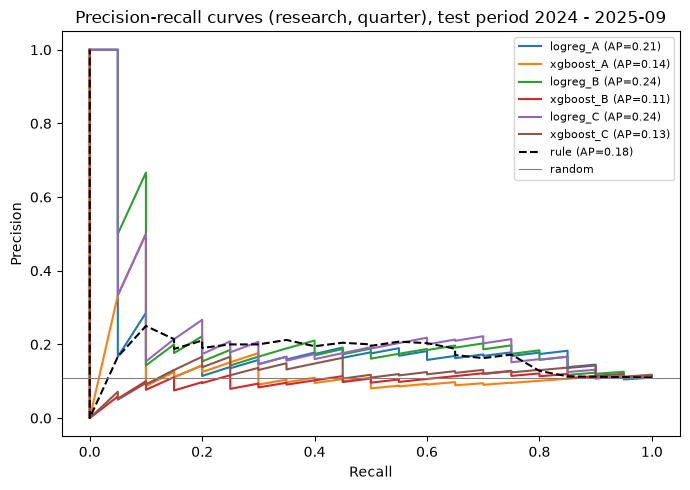

In [31]:
# ---------------- Figures ----------------
fig, ax = plt.subplots(figsize=(7, 5))
for name, (_, _, p) in fitted.items():
    pr, rc, _ = precision_recall_curve(test["y_fh"], p)
    ax.plot(rc, pr, label=f"{name} (AP={average_precision_score(test['y_fh'], p):.2f})")
pr, rc, _ = precision_recall_curve(test["y_fh"], rule)
ax.plot(rc, pr, "k--", label=f"rule (AP={average_precision_score(test['y_fh'], rule):.2f})")
ax.axhline(test["y_fh"].mean(), color="grey", lw=0.8, label="random")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title(f"Precision-recall curves ({MODE}, {UNIT}), test period 2024 - 2025-09")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGS / f"pr_curves_{TAG}.png", dpi=150)
plt.show()

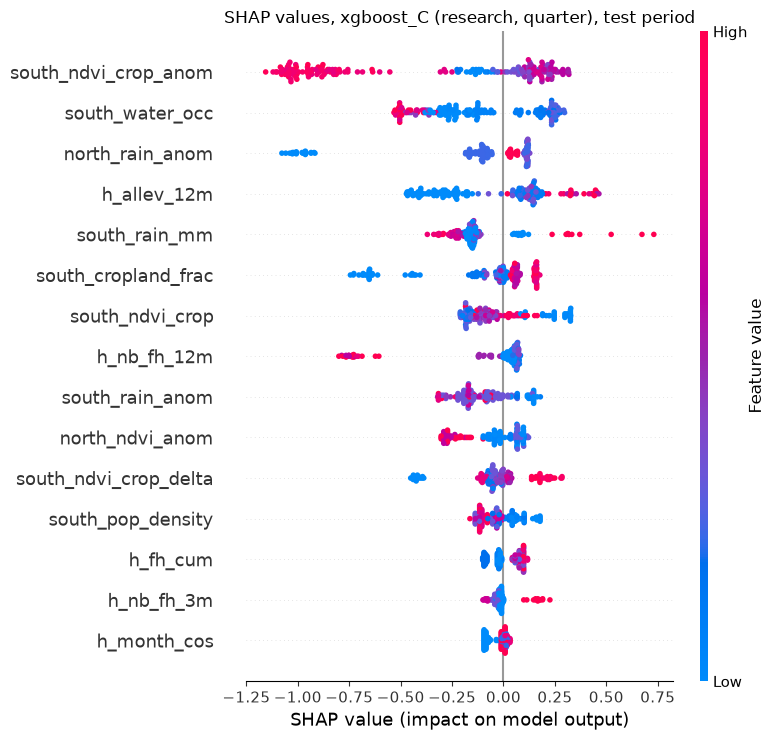


SHAP importance (mean |value|):
south_ndvi_crop_anom    0.4940
south_water_occ         0.2621
north_rain_anom         0.2291
h_allev_12m             0.2290
south_rain_mm           0.1853
south_cropland_frac     0.1567
south_ndvi_crop         0.1379
h_nb_fh_12m             0.1373
south_rain_anom         0.1371
north_ndvi_anom         0.1146


In [32]:
# SHAP (XGBoost trained on the same feature set as the selected model)
xgb_model, xgb_cols, _ = fitted[f"xgboost_{set_name}"]
sv = shap.TreeExplainer(xgb_model).shap_values(test[xgb_cols])
shap.summary_plot(sv, test[xgb_cols], show=False, max_display=15)
plt.title(f"SHAP values, xgboost_{set_name} ({MODE}, {UNIT}), test period")
plt.tight_layout()
plt.savefig(FIGS / f"shap_summary_{TAG}.png", dpi=150, bbox_inches="tight")
plt.show()
imp = pd.Series(np.abs(sv).mean(axis=0), index=xgb_cols).sort_values(ascending=False)
imp.to_csv(REPORTS / f"shap_importance_{TAG}.csv", header=["mean_abs_shap"])
print("\nSHAP importance (mean |value|):")
print(imp.round(4).head(10).to_string())

In [33]:
# ---------------- Predictions to the database ----------------
# 1) Out-of-sample on the test period; 2) forecast for the latest period whose features
#    are all available (research: the month after the conflict data; operational: the
#    period after the latest satellite month)
final = fit_select(kind, best_cols)[0]
final_all = final.fit(df[best_cols], df["y_fh"])  # refit on all labelled data
forecast = forecast[forecast[best_cols].notna().all(axis=1)]
forecast = forecast[forecast["ym"] == forecast["ym"].max()].copy()
assert forecast["dept_id"].nunique() == 26, "Incomplete forecast rows"
forecast["risk"] = final_all.predict_proba(forecast[best_cols])[:, 1]
pred = pd.concat([
    test[["dept_id", "ym"]].assign(model=f"{best_name}_{TAG}_test", risk=best_p),
    forecast[["dept_id", "ym", "risk"]].assign(model=f"{best_name}_{TAG}_forecast"),
])
with sqlite3.connect(DB) as con:
    con.execute("DELETE FROM predictions WHERE model LIKE ?", (f"%{TAG}%",))
    # Remove rows from earlier versions that had no mode in their name
    con.execute("DELETE FROM predictions WHERE model NOT LIKE '%research%' "
                "AND model NOT LIKE '%operational%'")
    con.executemany(
        "INSERT INTO predictions (dept_id, ym, model, risk) VALUES (?, ?, ?, ?)",
        pred[["dept_id", "ym", "model", "risk"]].itertuples(index=False),
    )
print(f"\n{len(pred)} predictions saved ({forecast['ym'].iloc[0]} = forecast)")


208 predictions saved (2025-10 = forecast)


In [34]:
# Per-department explanation of the forecast (logistic model only): contribution of each
# feature to the log-odds = standardised coefficient x standardised value
if best_name.startswith("logreg"):
    scaler = final_all.named_steps["standardscaler"]
    coef = final_all.named_steps["logisticregression"].coef_[0]
    z = scaler.transform(forecast[best_cols])
    rows_out = []
    for i, r in enumerate(forecast.itertuples()):
        for j, col in enumerate(best_cols):
            rows_out.append((r.dept_id, r.ym, f"contrib|{TAG}|{col}", float(z[i, j] * coef[j])))
            rows_out.append((r.dept_id, r.ym, f"value|{TAG}|{col}",
                             float(getattr(r, col))))
    with sqlite3.connect(DB) as con:
        con.execute("DELETE FROM features WHERE name LIKE ?", (f"%|{TAG}|%",))
        con.executemany("INSERT INTO features (dept_id, ym, name, value) VALUES (?, ?, ?, ?)",
                        rows_out)
    print(f"{len(rows_out)} explanation values saved for the forecast")

### Research model, monthly horizon

The same code for the next-month horizon (results in `reports/metrics_research_month.csv`).

In [35]:
import subprocess, sys
r = subprocess.run([sys.executable, str(ROOT / 'scripts' / 'train_models.py'), '--mode', 'research', '--unit', 'month'],
                   capture_output=True, text=True, cwd=ROOT)
print(r.stdout[-4000:] or r.stderr[-4000:])

Mode: research | unit of analysis: month
Model selection 2019-2023: 1560 rows (53 positives) | test 2024-2025: 546 rows (21 positives)
Feature sets: {'A': 13, 'B': 21, 'C': 23}

TEST RESULTS (2024 - 2025-09), mode = research, unit = month
           model  val_pr_auc  pr_auc  pr_auc_lo  pr_auc_hi  roc_auc  recall_top10  precision_top10  brier
rule_history_12m         NaN   0.065      0.036      0.121    0.651         0.190            0.073    NaN
        logreg_A       0.122   0.068      0.039      0.160    0.627         0.095            0.036  0.243
       xgboost_A       0.056   0.044      0.029      0.088    0.522         0.143            0.055  0.095
        logreg_B       0.120   0.054      0.032      0.113    0.609         0.095            0.036  0.230
       xgboost_B       0.157   0.044      0.026      0.080    0.533         0.143            0.055  0.134
        logreg_C       0.125   0.064      0.037      0.172    0.587         0.190            0.073  0.214
       xgboost_C   

## 8b. Operational model and current outlook

ACLED Research-tier data are published with a 12-month delay. The operational model therefore uses only what is really available when a forecast is issued: conflict history up to month t-13 (`o_` features), satellite data up to month t-1 and the season. It is trained and evaluated exactly like the research model, then produces a genuine forecast for the quarter after the latest satellite month.

The dashboard uses logistic regression with satellite features (`logreg_OB`), fixed by design: an early-warning tool must react to current conditions, and logistic regression is the most stable model with so few positive cases. The automatic selection is still reported (`reports/selection_operational_quarter.json`).

In [36]:
import subprocess, sys
r = subprocess.run([sys.executable, str(ROOT / 'scripts' / 'train_models.py'), '--mode', 'operational', '--unit', 'quarter', '--fixed-model', 'logreg_OB'],
                   capture_output=True, text=True, cwd=ROOT)
print(r.stdout[-4000:] or r.stderr[-4000:])

Mode: operational | unit of analysis: quarter
Model selection 2019-2023: 520 rows (47 positives) | test 2024-2025: 182 rows (20 positives)
Feature sets: {'OA': 10, 'OB': 20}

TEST RESULTS (2024 - 2025-09), mode = operational, unit = quarter
           model  val_pr_auc  pr_auc  pr_auc_lo  pr_auc_hi  roc_auc  recall_top10  precision_top10  brier
rule_history_12m         NaN   0.189      0.109      0.369    0.591          0.25            0.278    NaN
       logreg_OA       0.148   0.110      0.081      0.176    0.460          0.05            0.056  0.174
      xgboost_OA       0.255   0.186      0.074      0.324    0.411          0.10            0.111  0.138
       logreg_OB       0.141   0.214      0.106      0.412    0.663          0.25            0.278  0.220
      xgboost_OB       0.191   0.115      0.067      0.216    0.529          0.05            0.056  0.141

Selected by rolling-origin validation: xgboost_OA
Model used for predictions (fixed by design): logreg_OB

Standardised co

In [37]:
import subprocess, sys
r = subprocess.run([sys.executable, str(ROOT / 'scripts' / 'train_models.py'), '--mode', 'operational', '--unit', 'month'],
                   capture_output=True, text=True, cwd=ROOT)
print(r.stdout[-4000:] or r.stderr[-4000:])

Mode: operational | unit of analysis: month
Model selection 2019-2023: 1560 rows (53 positives) | test 2024-2025: 546 rows (21 positives)
Feature sets: {'OA': 10, 'OB': 20}

TEST RESULTS (2024 - 2025-09), mode = operational, unit = month
           model  val_pr_auc  pr_auc  pr_auc_lo  pr_auc_hi  roc_auc  recall_top10  precision_top10  brier
rule_history_12m         NaN   0.064      0.037      0.143    0.571         0.238            0.091    NaN
       logreg_OA       0.098   0.054      0.028      0.166    0.491         0.238            0.091  0.189
      xgboost_OA       0.106   0.047      0.026      0.121    0.424         0.143            0.055  0.094
       logreg_OB       0.104   0.059      0.034      0.155    0.542         0.190            0.073  0.168
      xgboost_OB       0.097   0.040      0.025      0.071    0.516         0.095            0.036  0.079

Selected by rolling-origin validation: xgboost_OA
Sensitivity (FH + AMB target): PR-AUC = 0.074 (prevalence 0.046)

SHAP impo

### Current outlook (operational model)

In [38]:
import sqlite3
import pandas as pd
with sqlite3.connect(ROOT / 'data' / 'app.db') as con:
    outlook = pd.read_sql("SELECT p.ym, d.department, d.province, p.risk FROM predictions p "
                          "JOIN departments d USING (dept_id) "
                          "WHERE p.model LIKE '%operational_quarter_forecast'", con)
outlook = outlook.sort_values('risk', ascending=False).reset_index(drop=True)
outlook.index += 1
print('Quarter starting', outlook['ym'].iloc[0])
outlook.head(10)

Quarter starting 2026-10


,ym,department,province,risk
1,2026-10,Monts de Lam,Logone Oriental,0.808007
2,2026-10,La Nya Pendé,Logone Oriental,0.773900
3,2026-10,La Nya,Logone Oriental,0.762330
4,2026-10,Kouh Ouest,Logone Oriental,0.761659
5,2026-10,Dodjé,Logone Occidental,0.731792
6,2026-10,La Pendé,Logone Oriental,0.702765
7,2026-10,Kouh Est,Logone Oriental,0.669401
8,2026-10,Barh-Sara,Mandoul,0.585989
9,2026-10,Mandoul Oriental,Mandoul,0.532360
10,2026-10,Bahr-Köh,Moyen-Chari,0.495014


## 9. Automated tests

Twelve tests check label and panel consistency, the absence of look-ahead in every feature, the absence of outcome leakage, the stored predictions and the dashboard (`tests/test_pipeline.py`).

In [39]:
r = subprocess.run([sys.executable, '-m', 'pytest', '-q', '--color=no', '-p', 'no:cacheprovider', str(ROOT / 'tests')],
                   capture_output=True, text=True, cwd=ROOT)
print(r.stdout[-3000:])

..............                                                           [100%]
14 passed in 5.42s



## 10. Dashboard code

The dashboard is a Streamlit application and runs outside the notebook:

```
streamlit run app/app.py
```

Its full code is reproduced below for reference.

```python
"""
Prototype - Early warning of farmer-herder conflict risk in southern Chad.

Tabs:
    Current outlook  : risk for the coming quarter (operational model: satellite data up to last
                       month + conflict history with the 12-month ACLED publication delay)
    Replay 2024-2025 : what the operational model would have flagged, quarter by quarter,
                       compared with the conflicts that actually happened
    Observed conflicts
    About the models

Run: streamlit run app/app.py
"""

import json
import sqlite3
from pathlib import Path

import folium
import pandas as pd
import streamlit as st
from streamlit_folium import st_folium

ROOT = Path(__file__).resolve().parents[1]
DB = ROOT / "data" / "app.db"
REPORTS = ROOT / "reports"
OPS = "operational_quarter"
TOP_N = 5  # departments flagged as highest priority

LABELS = {
    "south_ndvi_crop_anom": "Crop greenness vs normal (south)",
    "south_ndvi_crop": "Crop greenness (south)",
    "south_ndvi_crop_delta": "Change in crop greenness since previous month",
    "south_rain_mm": "Rainfall last month (south)",
    "south_rain_anom": "Rainfall vs normal (south)",
    "south_cropland_frac": "Share of cropland",
    "south_water_occ": "Surface water",
    "south_pop_density": "Population density",
    "north_ndvi_anom": "Pasture greenness vs normal (north, herd origin)",
    "north_rain_anom": "Rainfall vs normal (north, herd origin)",
    "o_fh_12m": "Conflicts in the department (latest known 12 months)",
    "o_fh_cum": "Conflicts in the department (all known history)",
    "o_broad_12m": "Communal violence (latest known 12 months)",
    "o_allev_12m": "All political violence (latest known 12 months)",
    "o_fatal_12m": "Conflict deaths (latest known 12 months)",
    "o_nb_fh_12m": "Conflicts in neighbouring departments (latest known 12 months)",
    "o_prov_fh_12m": "Conflicts elsewhere in the province (latest known 12 months)",
    "o_months_since_fh": "Months since last known conflict",
    "h_month_sin": "Season",
    "h_month_cos": "Season",
}

st.set_page_config(page_title="Farmer-Herder Conflict Risk - Southern Chad", layout="wide")


@st.cache_data
def load():
    with sqlite3.connect(DB) as con:
        depts = pd.read_sql("SELECT * FROM departments", con)
        panel = pd.read_sql("SELECT * FROM panel", con)
        preds = pd.read_sql("SELECT * FROM predictions", con)
        expl = pd.read_sql("SELECT * FROM features WHERE name LIKE ?", con,
                           params=(f"%|{OPS}|%",))
    return depts, panel, preds, expl


def quarter_label(ym):
    p = pd.Period(ym, freq="M")
    return f"{p.strftime('%b')}–{(p + 2).strftime('%b %Y')}"


def department_map(frame, value_col, legend, fmt="{:.0f}", key=None):
    """Choropleth of one value per department, with a hover tooltip."""
    fmap = folium.Map(location=[9.3, 16.8], zoom_start=7, tiles="OpenStreetMap")
    features = []
    for r in frame.itertuples():
        features.append({
            "type": "Feature",
            "id": r.dept_id,
            "geometry": json.loads(r.geometry)["features"][0]["geometry"],
            "properties": {"department": r.department, "province": r.province,
                           "value": fmt.format(getattr(r, value_col))},
        })
    gj = {"type": "FeatureCollection", "features": features}
    folium.Choropleth(
        geo_data=gj, data=frame, columns=["dept_id", value_col], key_on="feature.id",
        fill_color="YlOrRd", fill_opacity=0.75, line_opacity=0.4, legend_name=legend,
    ).add_to(fmap)
    folium.GeoJson(
        gj, style_function=lambda f: {"fillOpacity": 0, "weight": 0},
        tooltip=folium.GeoJsonTooltip(["department", "province", "value"],
                                      aliases=["Department", "Province", legend]),
    ).add_to(fmap)
    return st_folium(fmap, height=520, use_container_width=True, key=key)


def ranked(frame):
    frame = frame.copy()
    frame["risk_score"] = 100 * frame["risk"]
    frame["rank"] = frame["risk"].rank(ascending=False, method="first").astype(int)
    frame["priority"] = frame["rank"].map(
        lambda r: "Highest" if r <= TOP_N else ("Elevated" if r <= 2 * TOP_N else "Lower"))
    return frame.sort_values("rank")


depts, panel, preds, expl = load()
months = sorted(panel["ym"].unique())
data_end = months[-1]
ops = preds[preds["model"].str.contains(OPS)]
fc = ops[ops["model"].str.endswith("_forecast")]
replay = ops[ops["model"].str.endswith("_test")]
model_name = ops["model"].iloc[0].split(f"_{OPS}")[0] if not ops.empty else "-"

st.title("Farmer-Herder Conflict Risk — Southern Chad")
if not fc.empty:
    fc_ym = fc["ym"].iloc[0]
    sat_end = (pd.Period(fc_ym, freq="M") - 1).strftime("%B %Y")
    st.caption(
        f"Research prototype · satellite data up to **{sat_end}** · conflict data (ACLED, "
        f"published with a 12-month delay) up to **{pd.Period(data_end, freq='M').strftime('%B %Y')}** · "
        "department-level only."
    )

tab_now, tab_replay, tab_obs, tab_about = st.tabs(
    ["Current outlook", "Replay 2024–2025", "Observed conflicts", "About the models"])

# ---------------- Current outlook ----------------
with tab_now:
    if fc.empty:
        st.info("No forecast yet. Run: python scripts/train_models.py --mode operational "
                "--unit quarter --fixed-model logreg_OB")
    else:
        st.subheader(f"Conflict risk outlook for {quarter_label(fc_ym)}")
        frame = ranked(depts.merge(fc[["dept_id", "risk"]], on="dept_id"))
        left, right = st.columns([3, 2])
        with left:
            department_map(frame, "risk_score", "Relative risk score", "{:.0f}", key="now")
        with right:
            st.markdown(f"**Highest-priority departments ({TOP_N})**")
            st.dataframe(frame[["rank", "department", "province", "priority", "risk_score"]]
                         .rename(columns={"risk_score": "risk score"}).round(0),
                         hide_index=True, width="stretch", height=420)

        st.markdown("#### Why is a department at risk?")
        sel = st.selectbox("Department", frame["department"], index=0)
        dept_id = frame.loc[frame["department"] == sel, "dept_id"].item()
        e = expl[expl["dept_id"] == dept_id].copy()
        e["kind"] = e["name"].str.split("|").str[0]
        e["feature"] = e["name"].str.split("|").str[2]
        contrib = e[e["kind"] == "contrib"].set_index("feature")["value"]
        values = e[e["kind"] == "value"].set_index("feature")["value"]
        # Correlated conflict-history variables (and the two seasonal terms) are grouped, so
        # that their combined effect is shown instead of offsetting individual terms.
        hist = contrib[contrib.index.str.startswith("o_")]
        season = contrib[contrib.index.str.startswith("h_month")]
        sat = contrib[contrib.index.str.startswith(("south_", "north_"))]
        rows = [("Conflict history (latest known, at least 13 months old)", hist.sum(),
                 f"{values.get('o_fh_12m', 0):.0f} events in the department, "
                 f"{values.get('o_nb_fh_12m', 0):.0f} in neighbours (latest known 12 months)"),
                ("Season", season.sum(), quarter_label(fc_ym))]
        rows += [(LABELS.get(f, f), v, f"{values[f]:.3f}") for f, v in sat.items()]
        table = pd.DataFrame(rows, columns=["factor", "contribution", "current value"])
        table = table.reindex(table["contribution"].abs().sort_values(ascending=False).index)
        table["effect"] = table["contribution"].map(lambda v: "raises risk" if v > 0
                                                    else "lowers risk")
        table["strength"] = table["contribution"].abs().round(2)
        st.dataframe(table[["factor", "effect", "strength", "current value"]].head(7),
                     hide_index=True, width="stretch")
        st.caption("Effects come from the logistic model (standardised coefficient × "
                   "standardised value), for the department's current values. 'Current value' "
                   "is the latest observation available when the outlook was issued.")
        st.warning("Risk scores rank departments for prioritisation; they are not calibrated "
                   "probabilities. They must support, not replace, the judgement of people "
                   "who know the local situation.")

# ---------------- Replay ----------------
with tab_replay:
    if replay.empty:
        st.info("No replay predictions available.")
    else:
        st.markdown("If the tool had existed in 2024–2025 — using only the information that "
                    "would really have been available at the time — which departments would "
                    "it have flagged, and where did conflicts actually happen?")
        qs = sorted(replay["ym"].unique())
        q = st.select_slider("Quarter", options=qs, value=qs[-1], format_func=quarter_label)
        frame = ranked(depts.merge(replay[replay["ym"] == q][["dept_id", "risk"]],
                                   on="dept_id"))
        window = [m for m in months if m >= q][:3]
        obs = panel[panel["ym"].isin(window)].groupby("dept_id")["n_fh"].sum()
        frame["observed events"] = frame["dept_id"].map(obs).fillna(0).astype(int)

        hit = frame[(frame["observed events"] > 0)]
        c1, c2, c3 = st.columns(3)
        c1.metric("Departments with a conflict", len(hit))
        c2.metric(f"…of which flagged in the top {TOP_N}", int((hit["rank"] <= TOP_N).sum()))
        c3.metric(f"…of which flagged in the top {2 * TOP_N}",
                  int((hit["rank"] <= 2 * TOP_N).sum()))

        left, right = st.columns([3, 2])
        with left:
            department_map(frame, "risk_score", "Relative risk score", "{:.0f}", key="replay")
        with right:
            st.dataframe(frame[["rank", "department", "province", "observed events"]],
                         hide_index=True, width="stretch", height=480)

        # Summary over the whole test period
        allq = depts[["dept_id"]].merge(replay[["dept_id", "ym", "risk"]], on="dept_id")
        allq["rank"] = allq.groupby("ym")["risk"].rank(ascending=False, method="first")
        allq["events"] = [panel[(panel["dept_id"] == d) & panel["ym"].isin(
            [m for m in months if m >= y][:3])]["n_fh"].sum()
            for d, y in zip(allq["dept_id"], allq["ym"])]
        pos = allq[allq["events"] > 0]
        share = (pos["rank"] <= TOP_N).mean()
        st.info(f"Over the {len(qs)} test quarters, {share:.0%} of department-quarters with a "
                f"conflict were in the model's top {TOP_N} (a random ranking would reach "
                f"{TOP_N / 26:.0%}).")

# ---------------- Observed conflicts ----------------
with tab_obs:
    c1, c2, c3 = st.columns(3)
    provinces = sorted(depts["province"].unique())
    sel_prov = c1.multiselect("Provinces", provinces, default=provinces)
    start, end = c2.select_slider("Period", options=months, value=(months[0], months[-1]))
    target = c3.radio("Conflict definition", ["Strict (FH)", "Broad (FH + ambiguous)"])
    col = "n_fh" if target.startswith("Strict") else "n_broad"

    mask = panel["ym"].between(start, end) & panel["dept_id"].isin(
        depts.loc[depts["province"].isin(sel_prov), "dept_id"])
    sub = panel[mask]
    by_dept = sub.groupby("dept_id")[[col, "fatalities_fh"]].sum().reset_index()
    by_dept = depts.merge(by_dept, on="dept_id", how="left").fillna({col: 0, "fatalities_fh": 0})
    by_dept = by_dept[by_dept["province"].isin(sel_prov)]

    m1, m2, m3 = st.columns(3)
    m1.metric("Conflict events", int(sub[col].sum()))
    m2.metric("Fatalities (strict FH)", int(sub["fatalities_fh"].sum()))
    m3.metric("Department-months with ≥1 event", int((sub[col] > 0).sum()))

    left, right = st.columns([3, 2])
    with left:
        department_map(by_dept, col, "Events in period", key="obs")
    with right:
        st.bar_chart(sub.groupby("ym")[col].sum())
        st.dataframe(
            by_dept.sort_values(col, ascending=False)[["department", "province", col,
                                                        "fatalities_fh"]]
            .rename(columns={col: "events", "fatalities_fh": "fatalities"}),
            hide_index=True, width="stretch")
    st.caption("ACLED events manually classified as farmer-herder violence (blind validation: "
               f"Cohen's kappa = 0.83), January 2019 – {pd.Period(data_end, freq='M').strftime('%B %Y')}.")

# ---------------- About ----------------
with tab_about:
    st.markdown(
        "**Two models, two purposes.**\n\n"
        "- **Operational model** (used in *Current outlook* and *Replay*): uses only what is "
        "really available when a forecast is issued — satellite data up to the previous month "
        "and conflict history delayed by 12 months (ACLED publication delay).\n"
        "- **Research model**: uses conflict history up to the previous month, to answer the "
        "research question *do satellite indicators add information beyond conflict history?*\n\n"
        "All models are trained on 2019–2023 and evaluated once on 2024 – Sept 2025. "
        "PR-AUC is the main metric; a random ranking scores the prevalence.")
    c1, c2 = st.columns(2)
    mode = c1.radio("Model", ["operational", "research"], horizontal=True)
    unit = c2.radio("Horizon", ["quarter", "month"], horizontal=True)
    tag = f"{mode}_{unit}"
    mpath = REPORTS / f"metrics_{tag}.csv"
    if mpath.exists():
        m = pd.read_csv(mpath)
        st.dataframe(m[["model", "pr_auc", "pr_auc_lo", "pr_auc_hi", "roc_auc", "recall_top10",
                        "prevalence"]].round(3), hide_index=True, width="stretch")
    spath = REPORTS / f"selection_{tag}.json"
    if spath.exists():
        s = json.loads(spath.read_text(encoding="utf8"))
        note = (" Fixed by design: the outlook must react to current conditions (satellite "
                "data), and logistic regression is the most stable model with so few cases; "
                "automatic selection proved unstable.") if s["fixed_by_design"] else ""
        st.caption(f"Automatic selection: `{s['auto_selected']}` · used for predictions: "
                   f"`{s['used_for_predictions']}`.{note}")
    for name, title in [(f"pr_curves_{tag}.png", "Precision-recall curves"),
                        (f"shap_summary_{tag}.png", "Risk factors (SHAP, XGBoost)")]:
        if (REPORTS / "figures" / name).exists():
            st.image(str(REPORTS / "figures" / name), caption=title)

st.caption("Ethics: aggregated department-level data only; no ethnic or religious variables. "
           "Decision-support tool — not an automated decision system.")
```